In [1]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [3]:
df = pd.read_excel("datasets/Online Retail.xlsx").dropna(subset=['CustomerID'])
df = df[(df['Quantity'] > 0) & df['UnitPrice'] > 0]
df['TotalSpend'] = df['UnitPrice'] * df['Quantity']
print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalSpend  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom       15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom       22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  


In [25]:
customer_df = df.groupby('CustomerID').agg({
    'Quantity': 'sum',
    'UnitPrice': 'mean',
    'TotalSpend': 'sum',
    'Country': 'first'
}).reset_index()

In [26]:
threshold = customer_df['TotalSpend'].median()
customer_df['highvalue'] = (customer_df['TotalSpend'] > threshold).astype(int)
customer_df['Country'] = customer_df['Country'].astype('category').cat.codes

In [27]:
x = customer_df[['Quantity', 'UnitPrice', 'Country']]
y = customer_df['highvalue']

In [28]:
model = DecisionTreeClassifier(criterion='entropy', max_depth=4).fit(x,y)

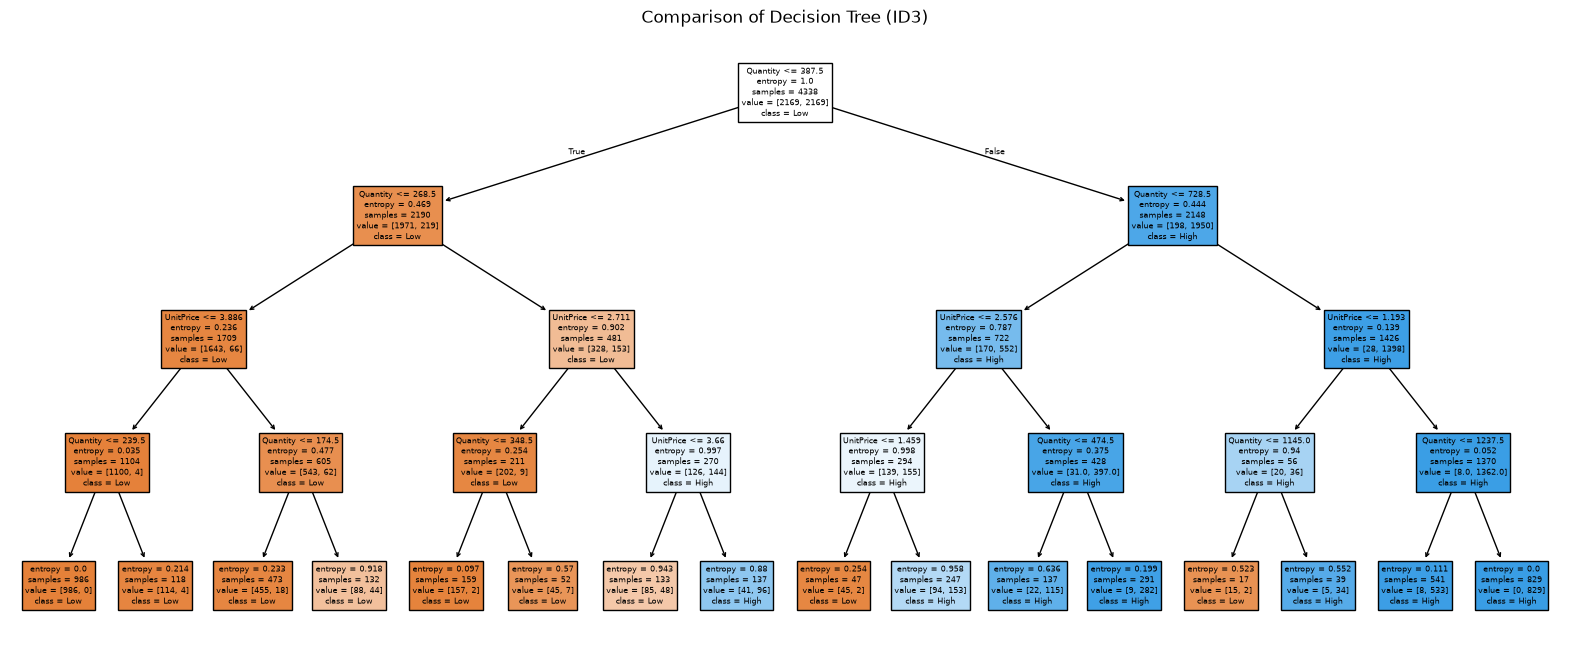

In [29]:
plt.figure(figsize=(20,8))
plot_tree(model, feature_names=x.columns, class_names=['Low', 'High'], filled=True)
plt.title("Comparison of Decision Tree (ID3)")
plt.show()